# Lecture 7 – Pandas III: reshaping, merging, and transforming

QSS 20 · Modern Statistical Computing · Fall 2026

### Agenda

- Granularity: what one row is.
- Reshaping the surname table into one guess per surname.
- Merging: inner, left, right, and outer joins, and how to check them.
- Transforming text with `.str`: why 1,194 voters find no surname.

## Where we left off

- Last lecture, 874 of 10,000 Florida voters (8.7 percent) had no recorded
  race. The share ran from 3.5 to 16.1 percent by county.
- Filling them with the most common race invented 874 white voters: the white
  share went from 0.681 to 0.709.

- Another approach: surname carries information about race. GARCIA, NGUYEN, and SMITH
  suggest different groups.

### Today's question

> **Can a voter's surname fill in a race the voter file does not record, and
> does it work equally well for every group?**

- Most voter files and many loan records do not record race. Researchers and
  government agencies then estimate it from surname and address. The Consumer
  Financial Protection Bureau, for example, uses such estimates in fair-lending
  reviews of loans whose records omit race.
- Florida records race for most voters, so we can check a surname guess
  against the recorded answer.

- If the guess fails more often for one group, every count built on it
  undercounts that group. Check the accuracy **for each group** as well as
  overall.

### Two tables

- `voters`: one row per registered voter. 
- `names`: one row per surname. The Census Bureau listed every surname held by
  at least 100 people in the 2000 Census, with the share of those people in
  each group.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_rows', 8)

# Sharp figures on high-resolution screens, from lecture 6.
%config InlineBackend.figure_format = 'retina'

voters = pd.read_csv('../../data/raw/FLVoters.csv',
                     keep_default_na=False, na_values=['NA'])
voters

,surname,county,VTD,age,gender,race
0,PIEDRA,115,66,58.0,f,white
1,LYNCH,115,13,51.0,m,white
2,CHESTER,115,103,63.0,m,NaN
3,LATHROP,115,80,54.0,m,white
...,...,...,...,...,...,...
9996,HILBERS,15,87,66.0,f,white
9997,JOHNSON,33,158,45.0,f,black
9998,GIL,86,1247,47.0,f,hispanic
9999,DAVIS,71,55,62.0,m,white


In [2]:
names = pd.read_csv("../../data/raw/names.csv", keep_default_na=False)
names

,surname,count,pctwhite,pctblack,pctapi,pcthispanic,pctothers
0,SMITH,2376206,73.342666,22.217778,0.399960,1.559844,2.479752
1,JOHNSON,1857160,61.550000,33.800000,0.420000,1.500000,2.730000
2,WILLIAMS,1534042,48.520000,46.720000,0.370000,1.600000,2.790000
3,BROWN,1380145,60.716072,34.543454,0.410041,1.640164,2.690269
...,...,...,...,...,...,...,...
151667,ZINNANTI,100,98.000000,0.000000,0.000000,1.000000,1.000000
151668,ZITTERICH,100,98.000000,1.000000,0.000000,1.000000,0.000000
151669,ZULU,100,6.000000,90.000000,0.000000,2.000000,2.000000
151670,ZUSI,100,100.000000,0.000000,0.000000,0.000000,0.000000


- `count` is how many people hold the surname. `pctwhite`, `pctblack`,
  `pctapi` (Asian and Pacific Islander), `pcthispanic`, and `pctothers` are
  percentages that sum to 100 for each surname.
- `keep_default_na=False` matters here too: `NULL` and `NAN` are real surnames
  in this list.

- The shares describe everyone in the country with that surname. They do
  not identify one person's race. A voter named SMITH can belong to any group.

## Granularity

- The **granularity** of a table is what one row represents.
- `voters`: one row per voter. `names`: one row per surname.

In [3]:
names['surname'].duplicated().sum(), voters['surname'].nunique()

(0, 6240)

- No surname appears twice in `names`. In `voters`, 10,000 rows hold 6,240
  distinct surnames: many voters share a surname.
- `surname` is the **key** that links the tables. Each voter should find at
  most one row in `names`, and one row in `names` can serve many voters. That
  is a **many-to-one** relationship.

### ❓ Question

The combined table should answer a question about voters. What should one row
of the combined table be, and how many rows should it have?

<details><summary>Answer</summary>

**One voter, 10,000 rows.** The merge attaches the surname shares to each
voter as extra columns. It should lose no voter and copy no voter.

</details>

## Reshaping: one guess per surname

- The simplest guess gives each voter the **largest group** for their surname.
- In `names` each group is a column, so "largest group for SMITH" compares
  values **across** a row. The tools from the last two lectures compare values
  **down** a column, within groups.

### `melt`: one row per surname and group

In [4]:
pct_cols = ['pctwhite', 'pctblack', 'pctapi', 'pcthispanic', 'pctothers']

long = names.melt(id_vars='surname', value_vars=pct_cols,
                  var_name='group', value_name='pct')
long.loc[long['surname'] == 'SMITH']

,surname,group,pct
0,SMITH,pctwhite,73.342666
151671,SMITH,pctblack,22.217778
303342,SMITH,pctapi,0.399960
455013,SMITH,pcthispanic,1.559844
606684,SMITH,pctothers,2.479752


- `id_vars` stays as it is. The `value_vars` columns become rows. `var_name`
  names the column that holds the old column names; `value_name` names the
  column that holds their values.
- SMITH is now five rows, one per group.

In [5]:
len(long), len(names) * 5

(758355, 758355)

- 151,671 surnames times 5 groups is 758,355 rows. Check the row count after
  every reshape.

### The largest group per surname

- In long form, "the largest group for each surname" is a `groupby` question.
  It is Route 1 of lecture 5's Activity 1: `.idxmax()`, then `.loc`.

In [6]:
top = long.loc[long.groupby('surname')['pct'].idxmax()]
top

,surname,group,pct
127185,AA,pctwhite,49.19
134036,AAB,pctwhite,95.69
40464,AABERG,pctwhite,94.89
82018,AABY,pctwhite,99.53
...,...,...,...
40550,ZYSKOWSKI,pctwhite,97.64
140754,ZYSMAN,pctwhite,100.00
39050,ZYWICKI,pctwhite,96.62
114850,ZYWIEC,pctwhite,99.30


In [7]:
top.loc[top["surname"].isin(["GARCIA", "NGUYEN", "SMITH", "WILLIAMS"])]

,surname,group,pct
455020,GARCIA,pcthispanic,90.819082
303398,NGUYEN,pctapi,95.930000
0,SMITH,pctwhite,73.342666
2,WILLIAMS,pctwhite,48.520000


In [8]:
len(top)

151671

- The table has one row per surname again, the granularity of `names`.

### Rename the groups with `.map`

- The Census names (`pctapi`, `pctothers`) differ from the voter file's
  (`asian`, `other`). A dictionary maps one set onto the other.

In [9]:
to_race = {'pctwhite': 'white', 
           'pctblack': 'black', 
           'pctapi': 'asian',
           'pcthispanic': 'hispanic', 
           'pctothers': 'other'}

guess = top.assign(guess=top['group'].map(to_race))[['surname', 'guess']]
guess['guess'].value_counts(dropna=False)

guess
white       130303
hispanic      8211
asian         6543
black         5870
other          744
Name: count, dtype: int64

- `.map(dict)` replaces each value with the dictionary's value for it. A value
  that is not in the dictionary becomes `NaN`, so count `NaN` after a map.
- The voter file has one group the Census list does not report separately,
  `native`. No surname can produce that guess.

### Back to wide: `pivot`

In [10]:
long.pivot(index='surname', columns='group', values='pct').loc[['GARCIA', 'SMITH']]

group,pctapi,pctblack,pcthispanic,pctothers,pctwhite
surname,,,,,
GARCIA,1.430143,0.490049,90.819082,1.090109,6.170617
SMITH,0.399960,22.217778,1.559844,2.479752,73.342666


- `pivot` reverses `melt`, because each (surname, group) pair appears once.
- A shortcut for the guess in wide form: `names[pct_cols].idxmax(axis=1)`
  returns the name of the largest column in each row. `axis=1` means "across
  the columns".

## Merging

- A **merge** (or **join**) puts two tables side by side, matching rows by a
  key.
- `left.merge(right, on='key', how=...)`. The **left** table is the one before
  `.merge`.

![Two small tables, people with five voters and lookup with four surnames, merged four ways. The inner join has 4 rows, only voters with a surname in the lookup. The left join has 5 rows, and voter 3, LE BORGNE, gets NaN for guess. The right join has 5 rows, and WILLIAMS gets NaN for voter. The outer join has 6 rows, including both unmatched rows](images/merge-types.png)

- **inner**: only keys found in both tables. 
- **left**: every row of the left table, with `NaN` where there is no match. 
- **right**: every row of the right table, with `NaN` where there is no match.
- **outer**: every row of both, with `NaN` where there is no match.
- One lookup row can serve several voters: the SMITH row matches voters 2 and 4.

### The small tables in code

In [11]:
people = pd.DataFrame({'voter': [1, 2, 3, 4, 5],
                       'surname': ['GARCIA', 'SMITH', 'LE BORGNE', 'SMITH', 'NGUYEN']})
lookup = pd.DataFrame({'surname': ['SMITH', 'GARCIA', 'WILLIAMS', 'NGUYEN'],
                       'guess': ['white', 'hispanic', 'white', 'asian']})

people.merge(lookup, on='surname', how='left')

,voter,surname,guess
0,1,GARCIA,hispanic
1,2,SMITH,white
2,3,LE BORGNE,NaN
3,4,SMITH,white
4,5,NGUYEN,asian


In [12]:
for how in ['inner', 'left', 'right', 'outer']:
    print(how, len(people.merge(lookup, on='surname', how=how)))

inner 4
left 5
right 5
outer 6


- The four surnames and their guesses are real rows of `guess`. LE BORGNE is
  a real Florida voter's surname that the Census list does not hold.
- When the key has different names in the two tables, use
  `left_on='...', right_on='...'` in place of `on=`.

### ❓ Question

By mistake, `lookup` holds the SMITH row **twice**:

```python
lookup2 = pd.concat([lookup, lookup.loc[lookup['surname'] == 'SMITH']],
                    ignore_index=True)
people.merge(lookup2, on='surname', how='inner')
```

How many rows does the inner join have now?

<details><summary>Answer</summary>

**6.** Voters 2 and 4 each match both SMITH rows, which gives 4 SMITH rows,
plus GARCIA and NGUYEN. A repeated key in the lookup table copies rows, and
pandas gives no warning.

</details>

### A repeated key copies rows

In [13]:
lookup2 = pd.concat([lookup, lookup.loc[lookup['surname'] == 'SMITH']],
                    ignore_index=True)
people.merge(lookup2, on='surname', how='inner')

,voter,surname,guess
0,1,GARCIA,hispanic
1,2,SMITH,white
2,2,SMITH,white
3,4,SMITH,white
4,4,SMITH,white
5,5,NGUYEN,asian


### The real merge

In [14]:
for how in ['left', 'inner', 'right', 'outer']:
    print(how, len(voters.merge(names, on='surname', how=how)))

left 10000
inner 8806
right 155422
outer 156616


- **left, 10,000:** every voter once, because each surname appears at most
  once in `names`.
- **inner, 8,806:** the voters whose surname is in the list. 1,194 voters have
  no match.
- **right, 155,422:** every surname in `names`: the 146,616 surnames that no
  voter holds, once each, plus the 8,806 matched voter rows.
- **outer, 156,616:** the right join plus the 1,194 unmatched voters.

- The question is about voters, so the voters define the rows. Use a **left**
  join with `voters` on the left.

### Check a merge: `indicator` and `validate`

In [15]:
merged = voters.merge(names, on='surname', how='left',
                      indicator=True, validate='many_to_one')
merged['_merge'].value_counts()

_merge
both          8806
left_only     1194
right_only       0
Name: count, dtype: int64

- `indicator=True` adds a column `_merge` that says where each row came from:
  `both`, `left_only`, or `right_only`.
- `validate='many_to_one'` states the relationship you expect: many voters to
  one surname row. If `names` held a surname twice, the merge would stop with
  an error instead of copying voters.

<div class="alert alert-info">

**Key idea.** Before a merge, write down each table's row unit, the key, the
relationship, and the number of rows you expect. After it, check the count and
`_merge`.

</div>

### ❓ Question

The Florida sample has 73 voters named SMITH. Suppose `names` held the SMITH
row twice.

```python
names_dup = pd.concat([names, names.loc[names['surname'] == 'SMITH']])
len(voters.merge(names_dup, on='surname', how='left'))
```

How many rows does the left join return?

<details><summary>Answer</summary>

**10,073.** Each of the 73 SMITH voters matches two rows and appears twice.
Every count that uses the merged table now counts those voters twice.

</details>

### `validate` catches the repeated key

In [16]:
names_dup = pd.concat([names, names.loc[names['surname'] == 'SMITH']])
len(voters.merge(names_dup, on='surname', how='left'))

10073

In [17]:
%xmode Minimal
voters.merge(names_dup, on='surname', how='left', validate='many_to_one')

Exception reporting mode: Minimal


MergeError: Merge keys are not unique in right dataset; not a many-to-one merge

- `%xmode Minimal` is a Jupyter command, not Python. It shortens every error
  message after it to its last line.
- The last line of the error says that keys repeat in the right table, so the
  merge is not many-to-one. With `validate`, a repeated key stops the code
  instead of copying rows.

<div class="alert alert-success">

### Activity 1 · How many rows?

`people` and `lookup2` are the small tables from the Question: SMITH appears
twice in each. **Without running anything**, write down how many rows each
merge returns.

```python
a = people.merge(lookup2, on='surname', how='left')
b = lookup2.merge(people, on='surname', how='left')
c = people.merge(lookup2, on='surname', how='outer')
```

Then run them in the cell below and check. Which `validate` value describes
these two tables: `'one_to_one'`, `'many_to_one'`, `'one_to_many'`, or
`'many_to_many'`?

</div>

In [18]:
print(people), print(lookup2)

   voter    surname
0      1     GARCIA
1      2      SMITH
2      3  LE BORGNE
3      4      SMITH
4      5     NGUYEN
    surname     guess
0     SMITH     white
1    GARCIA  hispanic
2  WILLIAMS     white
3    NGUYEN     asian
4     SMITH     white


(None, None)

### Counting rows

In [19]:
a = people.merge(lookup2, on='surname', how='left')
b = lookup2.merge(people, on='surname', how='left')
c = people.merge(lookup2, on='surname', how='outer')
len(a), len(b), len(c)

(7, 7, 8)

- **a, 7:** each SMITH voter matches 2 rows (4 rows), plus GARCIA, LE BORGNE,
  and NGUYEN.
- **b, 7:** each SMITH lookup row matches 2 voters (4 rows), plus GARCIA,
  NGUYEN, and WILLIAMS with no voter.
- **c, 8:** the 7 rows of `a` plus WILLIAMS.
- SMITH repeats on **both** sides, so the relationship is **many-to-many**:
  2 × 2 = 4 SMITH rows. In a table of voters, a many-to-many merge means
  that a key repeats where it should not.

## Transforming text: who does not match?

- `_merge` counts **voters**. Many voters share a surname, so count the
  distinct surnames that fail as well.
- A Python **set** holds unique values in no order. Two sets support the
  comparisons a merge makes.

In [20]:
voter_names = set(voters['surname'])
census_names = set(names['surname'])

(len(voter_names), len(voter_names & census_names),
 len(voter_names - census_names))

(6240, 5055, 1185)

- `a & b` keeps the values in both sets; `a - b` keeps the values in `a` and
  not in `b`. Of 6,240 distinct voter surnames, 5,055 are in the Census list
  and 1,185 are not.
- 1,185 surnames account for the 1,194 unmatched voters, so most unmatched
  surnames belong to one voter each.
- Sets give the distinct keys only. To keep the rows, use
  `voters.loc[~voters['surname'].isin(names['surname'])]`.

In [21]:
unmatched = merged.loc[merged['_merge'] == 'left_only', 'surname']
unmatched.sample(8, random_state=1)

541     WILLIAMSON-MUSC
9601            DRESPEL
2925              YULKE
8775      JONES HORNSBY
7758            LA RIVA
7406          RUIZ-CRUZ
6858          HEMPFIELD
8009          BEDINOTTI
Name: surname, dtype: object

- The Census list stops at surnames held by at least 100 people, so rare
  surnames have no row. Other misses are hyphenated names or names with a space.

### The `.str` accessor

- `.str` applies a string method to **every value** of a Series, the way
  arithmetic applies to every number.

In [22]:
hyphen = unmatched.str.contains('-')
space = unmatched.str.contains(' ')

hyphen.sum(), space.sum(), (hyphen & space).sum(), (~hyphen & ~space).sum()

(131, 169, 4, 898)

- 131 unmatched surnames contain a hyphen and 169 contain a space; 4 contain
  both. The other 898 are not in the list: fewer than 100 people held each of
  them in 2000, or the voter file spells them differently.

### Can a cleaned key match?

In [23]:
first_part = unmatched.loc[hyphen].str.split('-').str[0]
first_part.head(3)

46    SQUIRES
77     LAFOND
81     JORDAN
Name: surname, dtype: object

In [24]:
first_part.isin(names['surname']).sum()

117

- `.str.split('-')` turns each value into a list of parts; `.str[0]` takes the
  first part. 117 of the 131 hyphenated names match on their first part.

In [25]:
unmatched.loc[space].str.replace(' ', '').isin(names['surname']).sum()

48

- Removing the space turns VAN ASPEREN into VANASPEREN; 48 of the 169 then
  match.
- Each cleaning rule is a choice. For LAFOND-BRYANT, the hyphen rule keeps
  LAFOND and drops BRYANT. Record every change you make to a key. The rest of this
  lecture keeps the plain key, so every number traces back to one merge.

<div class="alert alert-info">

**Key idea.** A merge matches keys exactly. Look at the unmatched keys, clean
them with `.str` where a rule is defensible, and report what you changed.

</div>

### `.apply` on a Series

- `.apply(func)` runs a Python function on every value. It works for any
  function, but it runs one value at a time, so it is slower.

In [26]:
unmatched.apply(len).head(3)

7     10
27     8
35    15
Name: surname, dtype: int64

In [27]:
unmatched.str.len().head(3)

7     10
27     8
35    15
Name: surname, dtype: int64

- Both give the same numbers. Use `.str` or another built-in method when one
  exists, and `.apply` when none does.

## Does the surname guess right?

In [28]:
guessed = voters.merge(guess, on='surname', how='left',
                       indicator=True, validate='many_to_one')
guessed['_merge'].value_counts()

_merge
both          8806
left_only     1194
right_only       0
Name: count, dtype: int64

- The merge finds the same 8,806 matches, because `guess` has one row per
  surname, like `names`.

In [29]:
known = guessed.loc[guessed['race'].notna() & (guessed['_merge'] == 'both')]
len(known), (known['guess'] == known['race']).mean()

(8033, 0.7912361508776298)

- 8,033 voters have both a recorded race and a surname in the list. The guess
  is right for **79.1 percent** of them.

### ❓ Question

The guess is right for 79.1 percent of voters. Is it right for about 79
percent of **each** group?

<details><summary>Answer</summary>

**No.** It is right for 95.0 percent of white voters and 84.7 percent of
Hispanic voters, and for 16.2 percent of Black voters.

</details>

### Accuracy by group

In [30]:
by_race = (
    known
    .assign(correct=known['guess'] == known['race'])
    .groupby('race')['correct']
    .agg(['size', 'mean'])
)
by_race.round(3)

,size,mean
race,,
asian,140,0.564
black,1080,0.162
hispanic,1024,0.847
native,26,0.000
other,255,0.004
white,5508,0.950


- White 95.0 percent, Hispanic 84.7, Asian 56.4, Black **16.2**. The guess
  cannot be right for a Native American voter, and it is right for almost no
  voter in `other`.
- The overall 79.1 percent is high because white voters are 69 percent of
  this table.

### Where do the wrong guesses go?

In [31]:
known.pivot_table(index='race', columns='guess', values='surname',
                  aggfunc='size', fill_value=0)

guess,asian,black,hispanic,other,white
race,,,,,
asian,79,4,14,2,41
black,3,175,10,1,891
hispanic,7,4,867,0,146
native,1,1,2,0,22
other,11,16,39,1,188
white,19,61,191,3,5234


- Rows are the recorded race; columns are the guess. The guess calls **891 of
  the 1,080** Black voters white.
- `fill_value=0` is right here: an empty cell means no voters, a count of zero.

### How many voters would each group get?

- A count built on the guess gives each group its number of guesses. Compare
  it with the recorded count for the same 8,033 voters.

In [32]:
recorded = known['race'].value_counts()
guessed_n = known['guess'].value_counts()
recorded, guessed_n

(race
 white       5508
 black       1080
 hispanic    1024
 other        255
 asian        140
 native        26
 Name: count, dtype: int64,
 guess
 white       6522
 hispanic    1123
 black        261
 asian        120
 other          7
 Name: count, dtype: int64)

- The two Series hold the same groups in a different order, and `guessed_n`
  has no `native` row: no surname produces that guess.

### ❓ Question

```python
guessed_n - recorded
```

The two Series are in different orders, and only `recorded` has `native`.
What is the result for `black`, and what is it for `native`?

<details><summary>Answer</summary>

**black: -819. native: `NaN`.** pandas matches the rows by index label, not by
position, so `black` is 261 - 1,080. `native` has no partner, so the result is
`NaN`.

</details>

### Arithmetic lines up labels

In [33]:
guessed_n - recorded

asian        -20.0
black       -819.0
hispanic      99.0
native         NaN
other       -248.0
white       1014.0
Name: count, dtype: float64

- Arithmetic between two Series first matches index labels. The result holds
  **every** label from either side, sorted. A label found on only one side gets
  `NaN`.
- That is an outer join on the index. pandas gives no warning.

In [34]:
guessed_n.sub(recorded, fill_value=0)

asian        -20.0
black       -819.0
hispanic      99.0
native       -26.0
other       -248.0
white       1014.0
Name: count, dtype: float64

- `.sub(other, fill_value=0)` treats a missing label as 0. Here that is right:
  the guess named no voter `native`, so the guessed count is 0.
- `.add`, `.mul`, and `.div` take `fill_value` too. Choose it from what a
  missing label means, as with `fill_value` in `pivot_table`.

### Side by side: `.join`

- The difference alone hides the two counts. Put them in one table, matched by
  group.

In [35]:
counts = (recorded.rename('recorded').to_frame()
          .join(guessed_n.rename('guessed')))
counts

,recorded,guessed
race,,
white,5508,6522.0
black,1080,261.0
hispanic,1024,1123.0
other,255,7.0
asian,140,120.0
native,26,NaN


- `.join` merges on the **index**. It is a left join by default, so every
  recorded group stays and `native` gets `NaN`.
- `merge` does the same with `left_index=True, right_index=True,
  how='left'`. Use those arguments when the key is the index rather than a
  column.

- Counted by guess, these voters include **261** Black voters; the file
  records **1,080**. White voters rise from 5,508 to 6,522.

### ❓ Question

Why does the surname guess miss most Black voters? Look at these rows.

```python
names.loc[names['surname'].isin(['WILLIAMS', 'JOHNSON', 'JONES', 'JACKSON'])]
```

<details><summary>Answer</summary>

Many Black Americans hold surnames that more white Americans hold. WILLIAMS is
48.5 percent white and 46.7 percent Black, so the largest group is white, and
the guess calls every WILLIAMS white. Surnames where Black Americans are the
largest group, such as JACKSON, are fewer.

</details>

### The surnames behind the misses

In [36]:
names.loc[names['surname'].isin(['WILLIAMS', 'JOHNSON', 'JONES', 'JACKSON'])]

,surname,count,pctwhite,pctblack,pctapi,pcthispanic,pctothers
1,JOHNSON,1857160,61.550000,33.800000,0.420000,1.500000,2.730000
2,WILLIAMS,1534042,48.520000,46.720000,0.370000,1.600000,2.790000
4,JONES,1362755,57.690000,37.730000,0.350000,1.440000,2.790000
17,JACKSON,666125,41.925807,53.014699,0.309969,1.529847,3.219678


In [37]:
known.loc[known['race'] == 'black', 'surname'].value_counts().head(5)

surname
WILLIAMS    26
JONES       19
JOHNSON     19
BROWN       16
DAVIS       14
Name: count, dtype: int64

- The most common surnames among Black voters in the sample are WILLIAMS,
  JONES, and JOHNSON. The guess calls all three white.

<div class="alert alert-success">

### Activity 2 · Accuracy by group, in one figure

Draw the `mean` column of `by_race` as a horizontal bar chart, with labeled
axes and a title. Put the number of voters in each group into the labels or
the title.

Then write one sentence that answers today's question.

</div>

### The accuracy chart

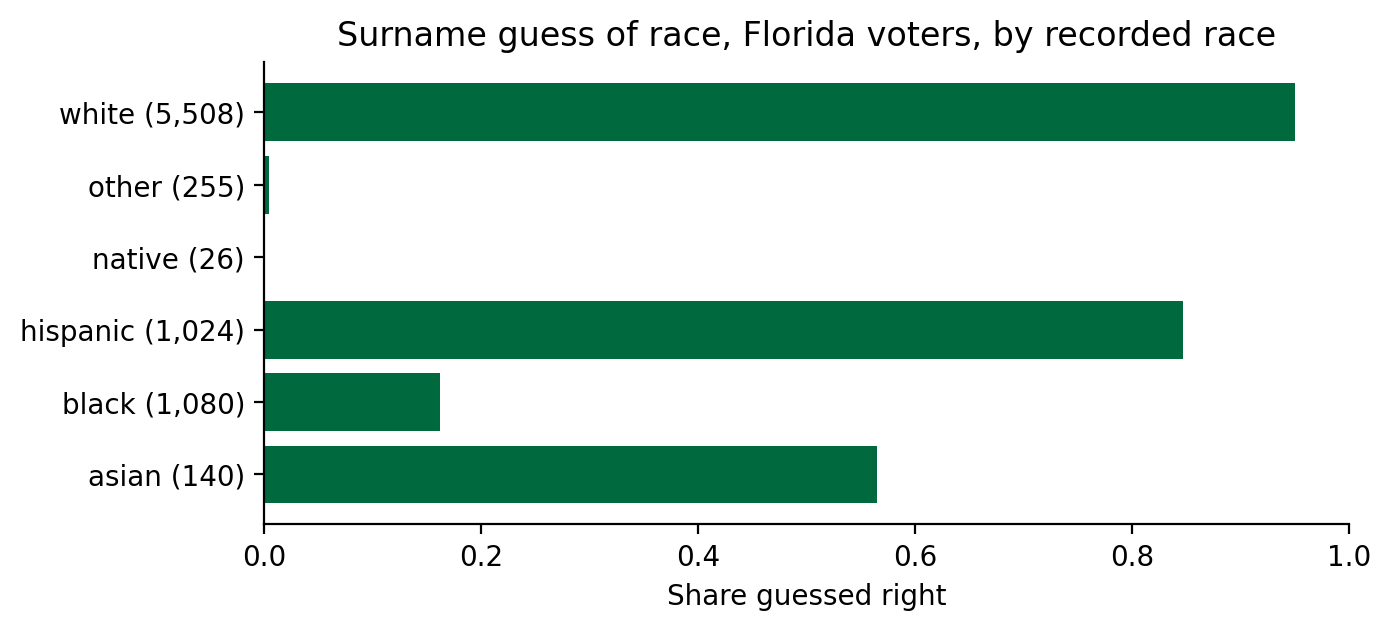

In [38]:
labels = [f'{race} ({n:,})' for race, n in zip(by_race.index, by_race['size'])]

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(labels, by_race['mean'], color='#00693e')
ax.set(xlabel='Share guessed right', xlim=(0, 1),
       title='Surname guess of race, Florida voters, by recorded race')
ax.spines[['top', 'right']].set_visible(False);

- A surname works well for white and Hispanic voters and badly for Black
  voters. Overall accuracy hides that difference.

### Filling the 874

In [39]:
missing = guessed.loc[guessed['race'].isna()]
missing['_merge'].value_counts()

_merge
both          773
left_only     101
right_only      0
Name: count, dtype: int64

In [40]:
missing['guess'].value_counts()

guess
white       654
hispanic     91
black        22
asian         6
Name: count, dtype: int64

- 773 of the 874 voters with no race have a surname in the list. The guess
  would call 654 of them white, 91 Hispanic, 22 Black, and 6 Asian.
- Among voters with a recorded race, 13.1 percent are Black. The guess labels
  22 of 773, 2.8 percent, of the missing voters Black.

- The race of the missing voters is unknown, and they may differ from the
  rest. The guess's known error, calling most Black voters white, would still
  push any count of Black voters down.

## What we found

- A surname alone guesses the recorded race right for **79.1 percent** of the
  Florida voters in the Census list. The accuracy depends on the group: 95.0
  percent for white voters, 84.7 for Hispanic voters, and **16.2** for Black
  voters.
- Filling the missing race from surnames would undercount Black voters.

- The shares describe a name across the whole country. The accuracy holds for
  this Florida sample; in a state where groups hold different surnames, the
  numbers would differ.

### The next idea: where a voter lives

- The voter file also records `county` and `VTD`, the voting district. A second
  Census table gives, for each district, the share of residents in each group.

In [41]:
districts = pd.read_csv('../../data/raw/FLCensusVTD.csv')
districts.head(3)

,county,VTD,total.pop,white,black,hispanic,api,others
0,1,46,4482,0.613788,0.187193,0.120928,0.053324,0.024766
1,1,31,5470,0.674223,0.120110,0.108592,0.071298,0.025777
2,1,55,3165,0.631596,0.208531,0.101106,0.021485,0.037283


In [42]:
len(voters.merge(districts, on='VTD', how='left'))

230187

- A VTD number repeats across counties, so `VTD` alone does not identify a
  district. The merge on `VTD` alone copies voters into 230,187 rows.

In [43]:
wrong = voters.merge(districts, on='VTD', how='left')
wrong[['surname', 'VTD', 'county_x', 'county_y']].head(4)

,surname,VTD,county_x,county_y
0,PIEDRA,66,115,1
1,PIEDRA,66,115,11
2,PIEDRA,66,115,15
3,PIEDRA,66,115,17


- Both tables have a `county` column, and it is not part of the key. pandas
  keeps both and adds `_x` (left table) and `_y` (right table) to the names.
- One voter, PIEDRA in county 115, now sits in districts of counties 1, 11,
  15, and 17. Columns ending in `_x` and `_y` are a sign that a shared column
  was left out of the key.
- To name the copies yourself, pass `suffixes=('_voter', '_district')`.

In [44]:
with_district = voters.merge(districts, on=['county', 'VTD'], how='left',
                             indicator=True, validate='many_to_one')
with_district['_merge'].value_counts()

_merge
both          10000
left_only         0
right_only        0
Name: count, dtype: int64

- For a **two-column key**, pass a list to `on=`. The (county, VTD) pair
  identifies a district, and all 10,000 voters match.
- The activity asks whether the district catches what the surname misses.

## Dates: when did registration close?

- A Florida voter must register 29 days before an election
  (Florida Statutes, section 97.055). On what date, and on what day of the
  week, did that period end for each presidential election since 2000?
- New table: one row per presidential election, typed in by hand.
- The issue: the values are dates, and a date stored as text does not
  behave like a date.

In [45]:
elections = pd.DataFrame({
    'year': [2000, 2004, 2008, 2012, 2016, 2020, 2024],
    'election_day': ['11/7/2000', '11/2/2004', '11/4/2008', '11/6/2012',
                     '11/8/2016', '11/3/2020', '11/5/2024'],
})
elections.dtypes

year             int64
election_day    object
dtype: object

### ❓ Question

```python
elections.sort_values('election_day')
```

Which election comes first?

<details><summary>Answer</summary>

**2004.** `election_day` holds text, and text sorts character by character.
`'11/2/2004'` comes before `'11/3/2020'` because `2` comes before `3`. The
year plays no part until the earlier characters tie.

</details>

### Text that looks like a date

In [46]:
elections.sort_values('election_day')

,year,election_day
1,2004,11/2/2004
5,2020,11/3/2020
2,2008,11/4/2008
6,2024,11/5/2024
3,2012,11/6/2012
0,2000,11/7/2000
4,2016,11/8/2016


- The order is 2004, 2020, 2008, 2024, 2012, 2000, 2016. It is sorted, but as
  text.

### `pd.to_datetime`

In [47]:
elections = elections.assign(
    election_day=pd.to_datetime(elections['election_day'],
                                format='%m/%d/%Y'))
elections.dtypes

year                     int64
election_day    datetime64[ns]
dtype: object

- `format=` spells out how the text is written: `%m` month, `%d` day, `%Y`
  four-digit year. `'Nov-2016'` would need `'%b-%Y'`. The Python documentation
  for `strftime` lists every code.
- The column is now `datetime64`, a **timestamp**. Sorting, comparison, and
  arithmetic now follow the calendar.

In [48]:
elections.sort_values('election_day')

,year,election_day
0,2000,2000-11-07
1,2004,2004-11-02
2,2008,2008-11-04
3,2012,2012-11-06
4,2016,2016-11-08
5,2020,2020-11-03
6,2024,2024-11-05


### The `.dt` accessor

In [49]:
elections['election_day'].dt.day_name()

0    Tuesday
1    Tuesday
2    Tuesday
3    Tuesday
4    Tuesday
5    Tuesday
6    Tuesday
Name: election_day, dtype: object

- `.dt` does for timestamps what `.str` does for text: it applies a method to
  every value. `.dt.year`, `.dt.month`, and `.dt.day_name()` pull out parts
  of each date.
- Every election fell on a Tuesday. Federal law sets Election Day as the
  Tuesday after the first Monday in November.

### Arithmetic with dates

In [50]:
elections = elections.assign(
    deadline=elections['election_day'] - pd.Timedelta(days=29))
elections.assign(weekday=elections['deadline'].dt.day_name())

,year,election_day,deadline,weekday
0,2000,2000-11-07,2000-10-09,Monday
1,2004,2004-11-02,2004-10-04,Monday
2,2008,2008-11-04,2008-10-06,Monday
3,2012,2012-11-06,2012-10-08,Monday
4,2016,2016-11-08,2016-10-10,Monday
5,2020,2020-11-03,2020-10-05,Monday
6,2024,2024-11-05,2024-10-07,Monday


- A **Timedelta** is a length of time. A timestamp minus a Timedelta is a new
  timestamp.
- Every deadline fell on a Monday, 29 days before a Tuesday. The table gives
  the date the rule sets. A holiday or an official extension can move the
  actual deadline, and this table cannot show that.

### ❓ Question

```python
elections['election_day'].diff()
```

`.diff()` subtracts each value from the one before it. The gap between two
elections is 1,456 days or 1,463 days, never 1,461 (four years). Why?

<details><summary>Answer</summary>

1,456 days is exactly 208 weeks, and 1,463 days is 209 weeks. Both dates
are Tuesdays, so the gap is a whole number of weeks. Four years of 365 or 366
days is not.

</details>

### Gaps between elections

In [51]:
elections['election_day'].diff()

0         NaT
1   1456 days
2   1463 days
3   1463 days
4   1463 days
5   1456 days
6   1463 days
Name: election_day, dtype: timedelta64[ns]

- A timestamp minus a timestamp is a Timedelta. The first row has no earlier
  election, so it gets `NaT`, "not a time", the missing value for dates.

In [52]:
elections.resample('10YS', on='election_day').size()

election_day
2000-01-01    3
2010-01-01    2
2020-01-01    2
Freq: 10YS-JAN, dtype: int64

- `resample` groups rows by time period: here, decades starting in 2000.
  It works like `groupby` with a date column as the key.
- `'10YS'` means "10 years, labeled by the start". `'MS'` is a month and `'W'`
  a week. Use `resample` when rows are dated events, such as posts or votes,
  and you need a count or mean for each period.

## Summary

| Goal | Write |
|---|---|
| Wide to long | `df.melt(id_vars=, value_vars=, var_name=, value_name=)` |
| Long to wide, one value per cell | `df.pivot(index=, columns=, values=)` |
| Row with the largest value, per group | `df.loc[df.groupby('g')['col'].idxmax()]` |
| Name of the largest column, per row | `df[cols].idxmax(axis=1)` |
| Replace values with a dictionary | `s.map({'old': 'new'})` |
| Join two tables on a key | `left.merge(right, on='key', how='left')` |
| Keys with different names | `left_on='a', right_on='b'` |
| A key of two columns | `on=['a', 'b']` |
| See where each row came from | `indicator=True`, then `df['_merge'].value_counts()` |
| Stop on a repeated key | `validate='many_to_one'` |
| Keys in one table but not the other | `a.loc[~a['key'].isin(b['key'])]` |
| String methods on every value | `s.str.contains('-')`, `s.str.split('-').str[0]`, `s.str.replace(' ', '')` |
| Any function on every value | `s.apply(func)` |
| Distinct keys in both, or in one only | `set(a) & set(b)`, `set(a) - set(b)` |
| Columns that share a name | `suffixes=('_left', '_right')` |
| Join on the index | `df.join(other)` or `merge(left_index=True, right_index=True)` |
| Arithmetic with missing labels | `s1.sub(s2, fill_value=0)` |
| Text to timestamps | `pd.to_datetime(s, format='%m/%d/%Y')` |
| Parts of a date | `s.dt.year`, `s.dt.day_name()` |
| Shift a date | `s - pd.Timedelta(days=29)` |
| Count per time period | `df.resample('MS', on='date').size()` |